
# Required Assignment 17.1: Comparing Classifiers

## 1. Business Understanding

This project uses data from a Portuguese bank's telephone
marketing campaigns. The bank contacts customers to offer
term deposits, but not every customer decides to subscribe.

The main business problem is figuring out which customers
are more likely to subscribe before the bank contacts them.

If the bank can predict which customers are more likely
to subscribe, it could spend less time calling customers
who are unlikely to be interested. This could help the bank
save money and make its marketing campaigns more effective.

**Research Question:**

How accurately can different machine learning models predict
whether a customer will subscribe to a term deposit?

I will compare four classification models:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree
- Support Vector Machine (SVM)

I will compare their performance and determine which model
would be the most useful for the bank.



## 2. Data Understanding

The dataset comes from the UCI Machine Learning Repository.
It contains information about customers and the results
of telephone marketing campaigns.

The target variable is `y`, which tells us whether a
customer subscribed to a term deposit.

A value of `yes` means the customer subscribed, while
`no` means they did not.

For this analysis, I will focus on customer characteristics
that the bank could know before making a phone call.
This makes the predictions more useful for future campaigns.


Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,258.29,2.57,962.48,0.17,0.08,93.58,-40.50,3.62,5167.04
std,10.42,259.28,2.77,186.91,0.49,1.57,0.58,4.63,1.73,72.25
min,17.00,0.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60
25%,32.00,102.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10
50%,38.00,180.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,319.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,98.00,4918.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10


... (6 outputs left out)

Unknown category counts:


,Count
default,8596
education,1730
housing,990
loan,990
job,330
marital,80


Training records: 30882
Testing records: 10294



## 4. Exploratory Data Analysis

Before building the models, I want to understand the
relationships between customer characteristics and
subscription outcomes.

I will examine the overall subscription distribution,
customer ages, job categories, and education levels.

These graphs can help identify patterns in the data,
although they do not prove that one characteristic
directly causes a customer to subscribe.


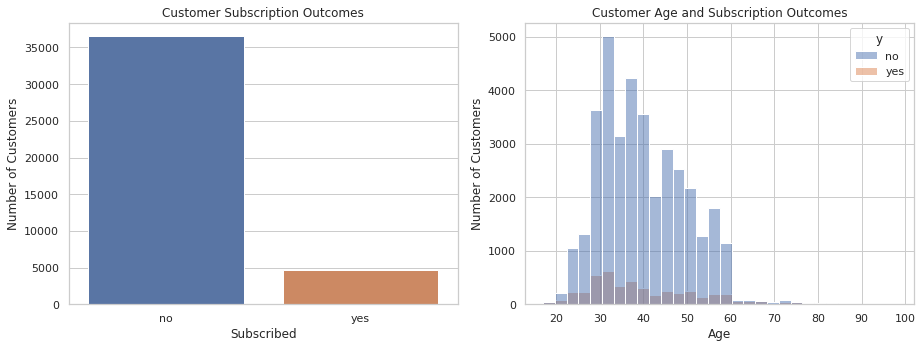

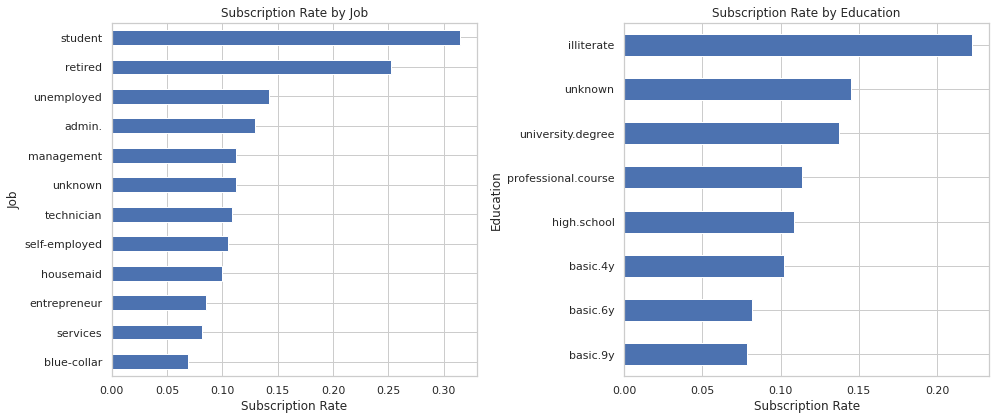


### Exploratory Data Findings

The graphs show that most customers did not subscribe
to the bank's term deposit.

Subscription rates also vary across different customer groups.

The job category with the highest observed subscription
rate was **student**, at **31.43%**.

The job category with the lowest observed subscription
rate was **blue-collar**, at **6.90%**.

The education category with the highest observed
subscription rate was **illiterate**, at
**22.22%**.

These differences suggest that customer characteristics
may help predict subscription outcomes.

However, some categories may contain fewer customers
than others, so these results should not automatically
be treated as reliable differences in customer behavior.



## 5. Baseline Model

Before comparing the classification models, I will create
a baseline model.

The baseline simply predicts the most common outcome,
which in this dataset is that a customer does not subscribe.

This helps show why accuracy can be misleading when the
classes are imbalanced.


Baseline Accuracy: 0.8873
Baseline Recall: 0.0



### Baseline Interpretation

The baseline model achieved an accuracy of
**88.73%**.

However, its recall for customers who actually subscribed
was **0.00%**.

This shows that high accuracy does not necessarily mean
a model is useful for the bank.

The bank wants to identify customers who might subscribe,
not just correctly predict the majority who will not.



## 6. Comparing Classification Models

I will now compare the four required classification models.

**Logistic Regression** is a relatively simple model that
estimates the probability of a customer subscribing.
Its coefficients can also help explain the predictions.

**K-Nearest Neighbors (KNN)** makes predictions based on
similar customers in the training data.

**Decision Trees** divide the data into groups based on
different customer characteristics.

**Support Vector Machines (SVM)** try to separate the
different classes using a decision boundary.

I will compare accuracy, precision, recall, F1 score,
and training time.

Precision tells us how many predicted subscribers
actually subscribed.

Recall tells us how many actual subscribers the
model successfully identified.

F1 combines precision and recall into one metric.


Initial Model Comparison:


... (6 outputs left out)

Final Model Comparison:


,Accuracy,Balanced Accuracy,Precision,Recall,F1,Average Precision,ROC AUC
Model,,,,,,,
Logistic Regression,0.5814,0.5940,0.1551,0.6103,0.2473,0.1925,0.6410
KNN,0.8873,0.5000,0.0000,0.0000,0.0000,0.2031,0.6304
Decision Tree,0.8861,0.5159,0.4400,0.0379,0.0698,0.1871,0.6168
SVM,0.8873,0.5000,0.0000,0.0000,0.0000,0.1657,0.5553



### Model Comparison Findings

The model selected through cross-validation was
**Logistic Regression**.

On the test dataset, this model achieved:

- **Average Precision:** 0.1925
- **Precision:** 15.51%
- **Recall:** 61.03%
- **F1 Score:** 0.2473

Recall is important because it shows how many actual
subscribers the model successfully identifies.

Precision is also important because contacting customers
costs time and money. The bank does not want to spend
resources contacting too many customers who are unlikely
to subscribe.

The best model should therefore be selected based on
the bank's marketing goals rather than accuracy alone.



## 9. Visualizing Model Performance

I will use a confusion matrix to examine the predictions
made by the selected model.

The confusion matrix shows:

- True positives: customers correctly predicted to subscribe.
- True negatives: customers correctly predicted not to subscribe.
- False positives: customers predicted to subscribe who did not.
- False negatives: customers who subscribed but were missed.

I will also compare ROC curves and precision-recall curves
for all four models.


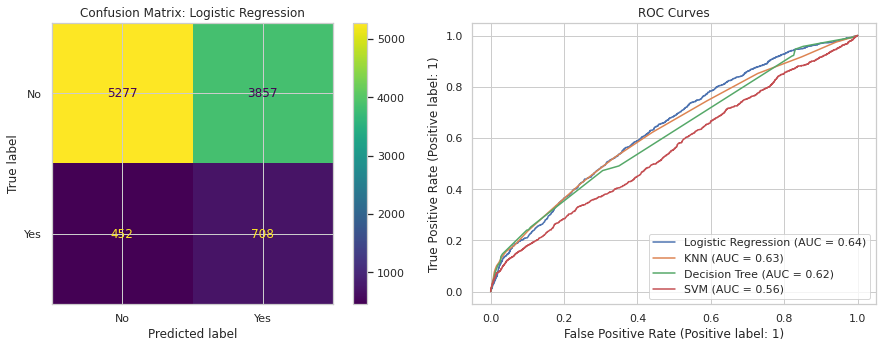

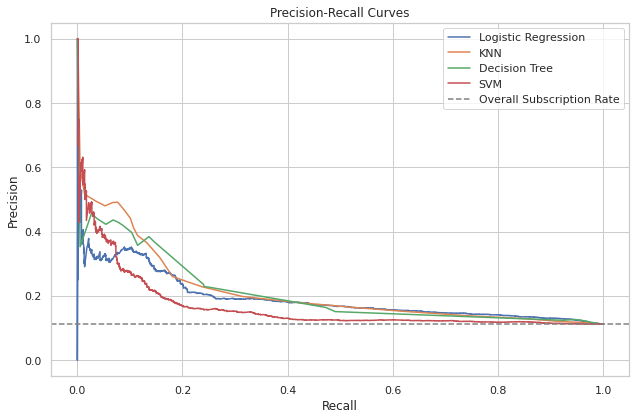


### Confusion Matrix Interpretation

The selected model produced the following results:

- **True Positives:** 708
- **True Negatives:** 5,277
- **False Positives:** 3,857
- **False Negatives:** 452

False positives represent customers the bank might
contact even though they would not subscribe.

False negatives represent potential subscribers
the bank might overlook.

The bank would need to decide which type of mistake
is more costly.

For example, if phone calls are inexpensive, the bank
might prefer higher recall so it misses fewer potential
subscribers.

If contacting customers is expensive, higher precision
may be more important.



## 10. Understanding Important Features

One advantage of logistic regression is that its
coefficients can help explain how the model makes predictions.

Positive coefficients increase the model's predicted
log-odds of subscribing.

Negative coefficients decrease the predicted log-odds.

Exponentiating a coefficient gives an odds multiplier.

For categorical variables, the coefficients should be
interpreted relative to the other encoded categories
and while holding the remaining features constant.

These coefficients show relationships in the model,
not necessarily cause-and-effect relationships.


Largest Logistic Regression Coefficients:


,Feature,Coefficient,Odds Multiplier
27,default_yes,-1.247,0.287
9,job_student,1.173,3.231
21,education_illiterate,-0.928,0.395
25,default_no,0.905,2.472
3,job_entrepreneur,-0.847,0.429
13,marital_divorced,-0.706,0.494
6,job_retired,0.675,1.964
16,marital_unknown,0.630,1.877
24,education_unknown,0.551,1.735
11,job_unemployed,0.453,1.572



### Coefficient Findings

The largest positive coefficient was associated with
**job_student**.

Its coefficient was
**1.173**.

The largest negative coefficient was associated with
**default_yes**.

Its coefficient was
**-1.247**.

These values help explain which encoded features have
stronger positive or negative relationships with
the model's predictions.

However, coefficient size can depend on how features
are encoded and scaled, so it should not automatically
be treated as a ranking of causal importance.



## 11. Business Application: Targeting Customers

The main purpose of this project is to help the bank
make better marketing decisions.

Instead of contacting every customer equally, the bank
could use model predictions to rank customers.

Customers with higher prediction scores could be
contacted first.

To see whether this approach might be useful, I will
compare the subscription rate among the highest-ranked
20% of customers against the overall subscription rate.

This gives an estimate of how much better targeted
marketing might perform compared to contacting
customers without using the model.


Selected Model: Logistic Regression
Overall Subscription Rate: 0.1127
Top 20% Subscription Rate: 1.904e-01
Marketing Lift: 1.69


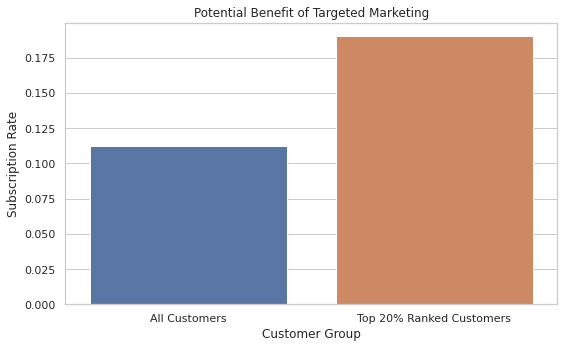


### Business Interpretation

The overall subscription rate in the test data was
**11.27%**.

Among the top 20% of customers ranked by the selected
model, the subscription rate was **19.04%**.

This represents a marketing lift of
**1.69 times** the overall rate.

This suggests that the model could help the bank
identify customers who are more likely to subscribe.

If the bank has limited time or resources, it could
prioritize higher-ranked customers instead of
contacting everyone equally.

However, these results come from historical data.
The bank would need to test this strategy in a real
campaign before assuming it will produce the same results.



## 12. Final Findings

The goal of this project was to compare four machine
learning classifiers and determine whether they could
help predict customer subscriptions.

After cleaning and exploring the data, I trained
Logistic Regression, KNN, Decision Tree, and SVM models.

I also used cross-validation and grid search to
compare different hyperparameter settings.

### Main Findings

**1. The dataset is imbalanced.**

Only about **11.27%** of customers in the
test dataset subscribed to a term deposit.

Because of this, accuracy by itself is not a good
measure of model performance.

**2. Different models performed differently.**

The four classifiers produced different results
for precision, recall, F1 score, and average precision.

This shows why it is important to compare multiple
models instead of assuming one approach will always
perform best.

**3. The selected model was Logistic Regression.**

It achieved the highest cross-validation average
precision among the models and settings tested.

Its test average precision was **0.1925**.

**4. Customer targeting showed potential value.**

The highest-ranked 20% of customers had a subscription
rate of **19.04%**, compared with an overall
rate of **11.27%**.

This suggests that machine learning could help the bank
make its marketing campaigns more focused.



## 13. Recommendations and Next Steps

Based on the results, I would recommend that the bank
continue testing **Logistic Regression** as a possible tool for
improving its telephone marketing campaigns.

The model could help rank customers based on their
likelihood of subscribing.

However, I would not recommend immediately replacing
the bank's existing marketing process.

### Recommendations

**1. Test the model in a small campaign.**

The bank could compare a group of customers selected
using the model against a group selected using its
current marketing approach.

This would help determine whether the model actually
improves subscription rates.

**2. Consider the cost of contacting customers.**

The bank should determine how much each phone call costs
and how much revenue a successful subscription generates.

This information could help choose a better decision
threshold and determine whether targeted marketing
would be financially worthwhile.

**3. Improve the available customer information.**

This analysis only used seven customer characteristics.

Additional information known before the call, such as
previous campaign outcomes or economic conditions,
might improve model performance.

Any additional variables should be checked to make
sure they would actually be available when the
bank makes its predictions.

**4. Test the model using more data.**

For training efficiency, this project used a stratified
sample of 5,000 training records.

Training on the full dataset could potentially improve
performance and provide more reliable results.

**5. Monitor performance over time.**

Customer behavior and economic conditions can change.

The bank should periodically evaluate the model and
retrain it when necessary.

### Conclusion

This project showed how machine learning classification
models can be used to study customer subscription behavior.

The results suggest that the bank may be able to use
predictive modeling to focus its marketing efforts on
customers who are more likely to subscribe.

Machine learning would not guarantee successful
subscriptions, but it could provide another useful
tool for making marketing decisions.



FINAL PROJECT SUMMARY
Dataset: 41176 records
Training Sample: 5000 records
Test Set: 10294 records
Models Compared: 4
Selected Model: Logistic Regression
Cross-Validation Average Precision: 0.1955
Test Average Precision: 0.1925
Test Recall: 0.6103
Overall Subscription Rate: 0.1127
Top 20% Subscription Rate: 0.1904
Marketing Lift: 1.69

Assignment analysis complete.


In [4]:

# ============================================================
# REQUIRED ASSIGNMENT 17.1: COMPARING CLASSIFIERS
# Bank Marketing Campaign Analysis
# ============================================================

# This project compares four machine learning classification models:
# Logistic Regression, K-Nearest Neighbors, Decision Trees, and SVM.
#
# The goal is to predict whether a customer will subscribe to a
# term deposit and determine how the bank could improve its marketing.


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

# Import libraries for data analysis and visualization
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

# Import tools for preparing data and training models
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Import the classification models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Import metrics used to compare model performance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    precision_recall_curve
)

# Set graph appearance and random state
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


# ============================================================
# 2. BUSINESS UNDERSTANDING
# ============================================================

display(Markdown("""
# Required Assignment 17.1: Comparing Classifiers

## 1. Business Understanding

This project uses data from a Portuguese bank's telephone
marketing campaigns. The bank contacts customers to offer
term deposits, but not every customer decides to subscribe.

The main business problem is figuring out which customers
are more likely to subscribe before the bank contacts them.

If the bank can predict which customers are more likely
to subscribe, it could spend less time calling customers
who are unlikely to be interested. This could help the bank
save money and make its marketing campaigns more effective.

**Research Question:**

How accurately can different machine learning models predict
whether a customer will subscribe to a term deposit?

I will compare four classification models:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree
- Support Vector Machine (SVM)

I will compare their performance and determine which model
would be the most useful for the bank.
"""))


# ============================================================
# 3. LOAD AND UNDERSTAND THE DATA
# ============================================================

display(Markdown("""
## 2. Data Understanding

The dataset comes from the UCI Machine Learning Repository.
It contains information about customers and the results
of telephone marketing campaigns.

The target variable is `y`, which tells us whether a
customer subscribed to a term deposit.

A value of `yes` means the customer subscribed, while
`no` means they did not.

For this analysis, I will focus on customer characteristics
that the bank could know before making a phone call.
This makes the predictions more useful for future campaigns.
"""))

# Load the dataset
# The CSV file should be in the same folder as the notebook
df = pd.read_csv("bank-additional-full.csv", sep=";")

# Display the size and first few rows
print("Dataset shape:", df.shape)
display(df.head())

# Check column information
print("\nColumn information:")
df.info()

# Look at basic statistics for numerical variables
print("\nDescriptive statistics:")
display(df.describe().round(2))

# Check for missing values
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check the distribution of the target variable
print("\nSubscription distribution:")
display(df["y"].value_counts(normalize=True).round(4))

subscription_rate = (df["y"] == "yes").mean()

display(Markdown(f"""
### Initial Findings

The dataset contains **{len(df):,} records** and
**{df.shape[1]} columns**.

Approximately **{subscription_rate:.2%}** of the customers
subscribed to a term deposit.

This means the dataset is imbalanced because most customers
did not subscribe.

This is important because a model could predict that every
customer will say no and still achieve fairly high accuracy.

Because of this, accuracy alone will not be enough to
determine which model performs best.
"""))


# ============================================================
# 4. DATA CLEANING AND PREPARATION
# ============================================================

display(Markdown("""
## 3. Data Cleaning and Preparation

Before training the models, the data needs to be cleaned
and prepared.

I will remove duplicate rows, select the variables used
for prediction, and convert the target into numerical values.

I will also encode categorical variables and standardize
numerical variables.

These steps are important because machine learning models
need numerical information to make predictions.

I am leaving out call duration because it is only known
after a phone call has taken place. Including it would make
the model less useful for deciding who to call beforehand.

I am also limiting the initial model to seven customer
characteristics. This makes the results easier to interpret,
although it may reduce prediction accuracy.
"""))

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Select features known before a customer is contacted
features = [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan"
]

# Separate the input features from the target variable
X = df[features].copy()

# Convert the target into binary values
# Yes = 1 and No = 0
y = (df["y"] == "yes").astype(int)

# Check whether the selected columns contain unknown values
unknown_counts = (
    X.select_dtypes(include="object")
    .eq("unknown")
    .sum()
    .sort_values(ascending=False)
)

print("Unknown category counts:")
display(unknown_counts.to_frame("Count"))

# Keep "unknown" as its own category
# It represents information the bank does not have

# Split the data into training and testing sets
# 75% is used for training and 25% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Separate numerical and categorical features
numeric_features = ["age"]

categorical_features = [
    col for col in features if col not in numeric_features
]

# Prepare numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Create a reusable pipeline function
def make_pipeline(model):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])


# ============================================================
# 5. EXPLORATORY DATA ANALYSIS
# ============================================================

display(Markdown("""
## 4. Exploratory Data Analysis

Before building the models, I want to understand the
relationships between customer characteristics and
subscription outcomes.

I will examine the overall subscription distribution,
customer ages, job categories, and education levels.

These graphs can help identify patterns in the data,
although they do not prove that one characteristic
directly causes a customer to subscribe.
"""))

# Plot the overall subscription distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df,
    x="y",
    ax=axes[0]
)

axes[0].set_title("Customer Subscription Outcomes")
axes[0].set_xlabel("Subscribed")
axes[0].set_ylabel("Number of Customers")

# Plot age distribution by subscription outcome
sns.histplot(
    data=df,
    x="age",
    hue="y",
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Customer Age and Subscription Outcomes")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

# Calculate subscription rates by job and education
job_rates = (
    df.groupby("job")["y"]
    .apply(lambda s: (s == "yes").mean())
    .sort_values()
)

education_rates = (
    df.groupby("education")["y"]
    .apply(lambda s: (s == "yes").mean())
    .sort_values()
)

# Create two horizontal bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

job_rates.plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title("Subscription Rate by Job")
axes[0].set_xlabel("Subscription Rate")
axes[0].set_ylabel("Job")

education_rates.plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("Subscription Rate by Education")
axes[1].set_xlabel("Subscription Rate")
axes[1].set_ylabel("Education")

plt.tight_layout()
plt.show()

# Calculate the highest and lowest subscription rates
highest_job = job_rates.idxmax()
lowest_job = job_rates.idxmin()

highest_education = education_rates.idxmax()

display(Markdown(f"""
### Exploratory Data Findings

The graphs show that most customers did not subscribe
to the bank's term deposit.

Subscription rates also vary across different customer groups.

The job category with the highest observed subscription
rate was **{highest_job}**, at **{job_rates.max():.2%}**.

The job category with the lowest observed subscription
rate was **{lowest_job}**, at **{job_rates.min():.2%}**.

The education category with the highest observed
subscription rate was **{highest_education}**, at
**{education_rates.max():.2%}**.

These differences suggest that customer characteristics
may help predict subscription outcomes.

However, some categories may contain fewer customers
than others, so these results should not automatically
be treated as reliable differences in customer behavior.
"""))


# ============================================================
# 6. BASELINE MODEL
# ============================================================

display(Markdown("""
## 5. Baseline Model

Before comparing the classification models, I will create
a baseline model.

The baseline simply predicts the most common outcome,
which in this dataset is that a customer does not subscribe.

This helps show why accuracy can be misleading when the
classes are imbalanced.
"""))

# Create and train the baseline model
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

# Evaluate the baseline
baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

baseline_recall = recall_score(
    y_test,
    baseline_predictions,
    zero_division=0
)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Recall:", round(baseline_recall, 4))

display(Markdown(f"""
### Baseline Interpretation

The baseline model achieved an accuracy of
**{baseline_accuracy:.2%}**.

However, its recall for customers who actually subscribed
was **{baseline_recall:.2%}**.

This shows that high accuracy does not necessarily mean
a model is useful for the bank.

The bank wants to identify customers who might subscribe,
not just correctly predict the majority who will not.
"""))


# ============================================================
# 7. MODELING
# ============================================================

display(Markdown("""
## 6. Comparing Classification Models

I will now compare the four required classification models.

**Logistic Regression** is a relatively simple model that
estimates the probability of a customer subscribing.
Its coefficients can also help explain the predictions.

**K-Nearest Neighbors (KNN)** makes predictions based on
similar customers in the training data.

**Decision Trees** divide the data into groups based on
different customer characteristics.

**Support Vector Machines (SVM)** try to separate the
different classes using a decision boundary.

I will compare accuracy, precision, recall, F1 score,
and training time.

Precision tells us how many predicted subscribers
actually subscribed.

Recall tells us how many actual subscribers the
model successfully identified.

F1 combines precision and recall into one metric.
"""))

# Use a stratified sample to reduce training time
# This keeps the project manageable on a regular computer
X_sample, _, y_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=5000,
    stratify=y_train,
    random_state=RANDOM_STATE
)

# Define the four models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "SVM": SVC(
        random_state=42
    )
}

# Store model results
initial_results = []

# Train and evaluate each model
for name, estimator in models.items():

    pipeline = make_pipeline(estimator)

    # Measure training time
    start_time = time.perf_counter()

    pipeline.fit(X_sample, y_sample)

    training_time = time.perf_counter() - start_time

    # Predict subscription outcomes
    predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    initial_results.append({
        "Model": name,
        "Training Time (s)": training_time,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Create a comparison table
initial_results = pd.DataFrame(
    initial_results
).set_index("Model")

print("Initial Model Comparison:")
display(initial_results.round(4))


# ============================================================
# 8. CROSS-VALIDATION AND HYPERPARAMETER TUNING
# ============================================================

display(Markdown("""
## 7. Cross-Validation and Hyperparameter Tuning

The default model settings might not provide the best results.

I will use GridSearchCV to test different hyperparameters
and find better settings for each model.

I will also use three-fold stratified cross-validation.

This means the training data is divided into three parts,
and the models are evaluated using different combinations
of training and validation data.

The main evaluation metric will be **average precision**.

I chose average precision because relatively few customers
subscribe. It summarizes how well a model balances precision
and recall across different prediction thresholds.

This is useful when the bank wants to rank customers by
their likelihood of subscribing.
"""))

# Create cross-validation folds
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Define hyperparameters to test
parameter_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },

    "KNN": {
        "model__n_neighbors": [11, 31, 61],
        "model__weights": ["uniform", "distance"]
    },

    "Decision Tree": {
        "model__max_depth": [3, 6, 10],
        "model__min_samples_leaf": [10, 50],
        "model__class_weight": [None, "balanced"]
    },

    "SVM": {
        "model__C": [0.1, 1],
        "model__kernel": ["linear", "rbf"]
    }
}

# Store the trained grid searches and results
searches = {}
cv_results = []

# Tune each classification model
for name, estimator in models.items():

    print("Tuning:", name)

    grid = GridSearchCV(
        estimator=make_pipeline(estimator),
        param_grid=parameter_grids[name],
        scoring="average_precision",
        cv=cv,
        n_jobs=1
    )

    # Fit the model using the training sample
    grid.fit(X_sample, y_sample)

    # Save the best model
    searches[name] = grid

    # Save the cross-validation results
    cv_results.append({
        "Model": name,
        "CV Average Precision": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

# Display the tuning results
cv_results = pd.DataFrame(
    cv_results
).set_index("Model")

display(cv_results)

# Identify the model with the best validation score
best_name = cv_results["CV Average Precision"].idxmax()

best_cv_score = cv_results.loc[
    best_name, "CV Average Precision"
]

display(Markdown(f"""
### Cross-Validation Results

Based on the cross-validation results,
**{best_name}** achieved the highest average precision
score of **{best_cv_score:.4f}**.

This suggests that it performed best among the models
and hyperparameter settings tested.

The final test data will now be used to evaluate how
well the tuned models perform on unseen customers.
"""))


# ============================================================
# 9. FINAL MODEL EVALUATION
# ============================================================

display(Markdown("""
## 8. Final Model Evaluation

After tuning the models, I will compare their performance
using the test dataset.

I will evaluate accuracy, balanced accuracy, precision,
recall, F1 score, average precision, and ROC AUC.

The final test set was not used to select the
hyperparameters, which helps provide a more realistic
estimate of model performance on unseen data.
"""))

# Store final evaluation results
final_results = []

# Evaluate each tuned model
for name, grid in searches.items():

    model = grid.best_estimator_

    # Make class predictions
    predictions = model.predict(X_test)

    # Get prediction scores
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]

    # Save evaluation metrics
    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_test, scores
        ),
        "ROC AUC": roc_auc_score(y_test, scores)
    })

# Create the final results table
final_results = pd.DataFrame(
    final_results
).set_index("Model")

print("Final Model Comparison:")
display(final_results.round(4))

# Select the model based on cross-validation
best_model = searches[best_name].best_estimator_

# Retrieve its test metrics
best_test_ap = final_results.loc[
    best_name, "Average Precision"
]

best_test_recall = final_results.loc[
    best_name, "Recall"
]

best_test_precision = final_results.loc[
    best_name, "Precision"
]

best_test_f1 = final_results.loc[
    best_name, "F1"
]

display(Markdown(f"""
### Model Comparison Findings

The model selected through cross-validation was
**{best_name}**.

On the test dataset, this model achieved:

- **Average Precision:** {best_test_ap:.4f}
- **Precision:** {best_test_precision:.2%}
- **Recall:** {best_test_recall:.2%}
- **F1 Score:** {best_test_f1:.4f}

Recall is important because it shows how many actual
subscribers the model successfully identifies.

Precision is also important because contacting customers
costs time and money. The bank does not want to spend
resources contacting too many customers who are unlikely
to subscribe.

The best model should therefore be selected based on
the bank's marketing goals rather than accuracy alone.
"""))


# ============================================================
# 10. VISUALIZING MODEL PERFORMANCE
# ============================================================

display(Markdown("""
## 9. Visualizing Model Performance

I will use a confusion matrix to examine the predictions
made by the selected model.

The confusion matrix shows:

- True positives: customers correctly predicted to subscribe.
- True negatives: customers correctly predicted not to subscribe.
- False positives: customers predicted to subscribe who did not.
- False negatives: customers who subscribed but were missed.

I will also compare ROC curves and precision-recall curves
for all four models.
"""))

# Create confusion matrix and ROC curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["No", "Yes"],
    ax=axes[0]
)

axes[0].set_title("Confusion Matrix: " + best_name)

# Plot ROC curves for all models
for name, grid in searches.items():

    RocCurveDisplay.from_estimator(
        grid.best_estimator_,
        X_test,
        y_test,
        name=name,
        ax=axes[1]
    )

axes[1].set_title("ROC Curves")

plt.tight_layout()
plt.show()

# Create precision-recall curves
fig, ax = plt.subplots(figsize=(9, 6))

for name, grid in searches.items():

    model = grid.best_estimator_

    # Get scores for each customer
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]

    # Calculate precision and recall
    precision, recall, _ = precision_recall_curve(
        y_test, scores
    )

    # Plot the curve
    ax.plot(
        recall,
        precision,
        label=name
    )

ax.axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label="Overall Subscription Rate"
)

ax.set_title("Precision-Recall Curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()

plt.tight_layout()
plt.show()

# Calculate confusion matrix values
best_predictions = best_model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
).ravel()

display(Markdown(f"""
### Confusion Matrix Interpretation

The selected model produced the following results:

- **True Positives:** {tp:,}
- **True Negatives:** {tn:,}
- **False Positives:** {fp:,}
- **False Negatives:** {fn:,}

False positives represent customers the bank might
contact even though they would not subscribe.

False negatives represent potential subscribers
the bank might overlook.

The bank would need to decide which type of mistake
is more costly.

For example, if phone calls are inexpensive, the bank
might prefer higher recall so it misses fewer potential
subscribers.

If contacting customers is expensive, higher precision
may be more important.
"""))


# ============================================================
# 11. INTERPRETING LOGISTIC REGRESSION
# ============================================================

display(Markdown("""
## 10. Understanding Important Features

One advantage of logistic regression is that its
coefficients can help explain how the model makes predictions.

Positive coefficients increase the model's predicted
log-odds of subscribing.

Negative coefficients decrease the predicted log-odds.

Exponentiating a coefficient gives an odds multiplier.

For categorical variables, the coefficients should be
interpreted relative to the other encoded categories
and while holding the remaining features constant.

These coefficients show relationships in the model,
not necessarily cause-and-effect relationships.
"""))

# Get the tuned logistic regression model
log_model = searches[
    "Logistic Regression"
].best_estimator_

# Get the numerical feature name
numeric_names = ["age"]

# Get the categorical feature names after one-hot encoding
categorical_names = (
    log_model.named_steps["preprocessor"]
    .named_transformers_["categorical"]
    .get_feature_names_out(categorical_features)
)

# Combine all feature names
feature_names = np.concatenate([
    numeric_names,
    categorical_names
])

# Retrieve logistic regression coefficients
coefficients = (
    log_model.named_steps["model"]
    .coef_[0]
)

# Create a coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds Multiplier": np.exp(coefficients)
})

# Sort by absolute coefficient size
coef_df = coef_df.reindex(
    coef_df["Coefficient"]
    .abs()
    .sort_values(ascending=False)
    .index
)

print("Largest Logistic Regression Coefficients:")
display(coef_df.head(12).round(3))

# Identify the largest positive and negative coefficients
largest_positive = coef_df.loc[
    coef_df["Coefficient"].idxmax()
]

largest_negative = coef_df.loc[
    coef_df["Coefficient"].idxmin()
]

display(Markdown(f"""
### Coefficient Findings

The largest positive coefficient was associated with
**{largest_positive['Feature']}**.

Its coefficient was
**{largest_positive['Coefficient']:.3f}**.

The largest negative coefficient was associated with
**{largest_negative['Feature']}**.

Its coefficient was
**{largest_negative['Coefficient']:.3f}**.

These values help explain which encoded features have
stronger positive or negative relationships with
the model's predictions.

However, coefficient size can depend on how features
are encoded and scaled, so it should not automatically
be treated as a ranking of causal importance.
"""))


# ============================================================
# 12. CUSTOMER TARGETING AND BUSINESS VALUE
# ============================================================

display(Markdown("""
## 11. Business Application: Targeting Customers

The main purpose of this project is to help the bank
make better marketing decisions.

Instead of contacting every customer equally, the bank
could use model predictions to rank customers.

Customers with higher prediction scores could be
contacted first.

To see whether this approach might be useful, I will
compare the subscription rate among the highest-ranked
20% of customers against the overall subscription rate.

This gives an estimate of how much better targeted
marketing might perform compared to contacting
customers without using the model.
"""))

# Get scores from the selected model
if hasattr(best_model, "decision_function"):

    ranking_scores = best_model.decision_function(X_test)

else:

    ranking_scores = best_model.predict_proba(X_test)[:, 1]

# Select the highest-ranked 20% of customers
top_n = int(np.ceil(0.20 * len(y_test)))

top_indices = np.argsort(ranking_scores)[-top_n:]

# Calculate subscription rate among top-ranked customers
top_rate = y_test.to_numpy()[top_indices].mean()

# Calculate overall subscription rate
overall_rate = y_test.mean()

# Calculate marketing lift
marketing_lift = top_rate / overall_rate

# Display results
print("Selected Model:", best_name)
print("Overall Subscription Rate:", round(overall_rate, 4))
print("Top 20% Subscription Rate:", round(top_rate, 4))
print("Marketing Lift:", round(marketing_lift, 2))

# Compare subscription rates visually
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    x=["All Customers", "Top 20% Ranked Customers"],
    y=[overall_rate, top_rate],
    ax=ax
)

ax.set_title("Potential Benefit of Targeted Marketing")
ax.set_ylabel("Subscription Rate")
ax.set_xlabel("Customer Group")

plt.tight_layout()
plt.show()

display(Markdown(f"""
### Business Interpretation

The overall subscription rate in the test data was
**{overall_rate:.2%}**.

Among the top 20% of customers ranked by the selected
model, the subscription rate was **{top_rate:.2%}**.

This represents a marketing lift of
**{marketing_lift:.2f} times** the overall rate.

This suggests that the model could help the bank
identify customers who are more likely to subscribe.

If the bank has limited time or resources, it could
prioritize higher-ranked customers instead of
contacting everyone equally.

However, these results come from historical data.
The bank would need to test this strategy in a real
campaign before assuming it will produce the same results.
"""))


# ============================================================
# 13. FINAL FINDINGS
# ============================================================

display(Markdown(f"""
## 12. Final Findings

The goal of this project was to compare four machine
learning classifiers and determine whether they could
help predict customer subscriptions.

After cleaning and exploring the data, I trained
Logistic Regression, KNN, Decision Tree, and SVM models.

I also used cross-validation and grid search to
compare different hyperparameter settings.

### Main Findings

**1. The dataset is imbalanced.**

Only about **{overall_rate:.2%}** of customers in the
test dataset subscribed to a term deposit.

Because of this, accuracy by itself is not a good
measure of model performance.

**2. Different models performed differently.**

The four classifiers produced different results
for precision, recall, F1 score, and average precision.

This shows why it is important to compare multiple
models instead of assuming one approach will always
perform best.

**3. The selected model was {best_name}.**

It achieved the highest cross-validation average
precision among the models and settings tested.

Its test average precision was **{best_test_ap:.4f}**.

**4. Customer targeting showed potential value.**

The highest-ranked 20% of customers had a subscription
rate of **{top_rate:.2%}**, compared with an overall
rate of **{overall_rate:.2%}**.

This suggests that machine learning could help the bank
make its marketing campaigns more focused.
"""))


# ============================================================
# 14. RECOMMENDATIONS AND NEXT STEPS
# ============================================================

display(Markdown(f"""
## 13. Recommendations and Next Steps

Based on the results, I would recommend that the bank
continue testing **{best_name}** as a possible tool for
improving its telephone marketing campaigns.

The model could help rank customers based on their
likelihood of subscribing.

However, I would not recommend immediately replacing
the bank's existing marketing process.

### Recommendations

**1. Test the model in a small campaign.**

The bank could compare a group of customers selected
using the model against a group selected using its
current marketing approach.

This would help determine whether the model actually
improves subscription rates.

**2. Consider the cost of contacting customers.**

The bank should determine how much each phone call costs
and how much revenue a successful subscription generates.

This information could help choose a better decision
threshold and determine whether targeted marketing
would be financially worthwhile.

**3. Improve the available customer information.**

This analysis only used seven customer characteristics.

Additional information known before the call, such as
previous campaign outcomes or economic conditions,
might improve model performance.

Any additional variables should be checked to make
sure they would actually be available when the
bank makes its predictions.

**4. Test the model using more data.**

For training efficiency, this project used a stratified
sample of 5,000 training records.

Training on the full dataset could potentially improve
performance and provide more reliable results.

**5. Monitor performance over time.**

Customer behavior and economic conditions can change.

The bank should periodically evaluate the model and
retrain it when necessary.

### Conclusion

This project showed how machine learning classification
models can be used to study customer subscription behavior.

The results suggest that the bank may be able to use
predictive modeling to focus its marketing efforts on
customers who are more likely to subscribe.

Machine learning would not guarantee successful
subscriptions, but it could provide another useful
tool for making marketing decisions.
"""))


# ============================================================
# 15. FINAL PROJECT SUMMARY
# ============================================================

# Print a short summary of the completed analysis
print("\n" + "=" * 55)
print("FINAL PROJECT SUMMARY")
print("=" * 55)

print("Dataset:", len(df), "records")
print("Training Sample:", len(X_sample), "records")
print("Test Set:", len(X_test), "records")
print("Models Compared:", len(models))
print("Selected Model:", best_name)
print("Cross-Validation Average Precision:", round(best_cv_score, 4))
print("Test Average Precision:", round(best_test_ap, 4))
print("Test Recall:", round(best_test_recall, 4))
print("Overall Subscription Rate:", round(overall_rate, 4))
print("Top 20% Subscription Rate:", round(top_rate, 4))
print("Marketing Lift:", round(marketing_lift, 2))

print("\nAssignment analysis complete.")


In [7]:
import subprocess

subprocess.run(["git", "--version"])

git version 2.25.1


CompletedProcess(args=['git', '--version'], returncode=0)

In [8]:

import os
import subprocess

# Your GitHub repository
repo = "https://github.com/Jmoorehead1/Bank-Marketing-Classification-Analysis.git"

# Find your notebook
notebook = "bank-marketing-classifiers.ipynb"

# Set up Git in the current folder
subprocess.run(["git", "init"], check=True)
subprocess.run(["git", "branch", "-M", "main"], check=True)

# Set your Git identity
subprocess.run(["git", "config", "user.name", "Jmoorehead1"], check=True)

# Set your email locally for Git commits
subprocess.run(["git", "config", "user.email", "Jmoorehead1@users.noreply.github.com"], check=True)

# Add your notebook
subprocess.run(["git", "add", notebook], check=True)

# Commit the notebook
subprocess.run(["git", "commit", "-m", "Add completed classification analysis"], check=True)

# Connect to your GitHub repository
subprocess.run(["git", "remote", "remove", "origin"], capture_output=True)
subprocess.run(["git", "remote", "add", "origin", repo], check=True)

print("Notebook committed locally. Ready to connect to GitHub.")


Initialized empty Git repository in /var/www/filebrowser/.projects/b07c225d-edef-42c7-9e3c-1462c1f1c515/.git/


error: refname refs/heads/master not found
fatal: Branch rename failed


CalledProcessError: Command '['git', 'branch', '-M', 'main']' returned non-zero exit status 128.